#**Classe A**

#Imagem 1



*   **Nome**: img001_original.jpg
*   **Classe**: Teclado - Classe A
*   **Parâmetros de captura**: ISO 1600, 1/20s, f/1.8, 4.69mm
*   **Tipo de degradação observada**: Ruído de Liminância (Granulação média)
*   **Hipótese**: Imagem foi tirada em um ambiente interno como iluminação artificial, posicionando o teclado sobre um lencol. A iluminação reduzida gera uma granulação visível em toda a fota. Esse ruído é especialmente fácil de notar nas partes mais claras e texturizadas do teclado da cama e nas sombras ao redor das bordas do teclado, resultando em uma perda geral de nitidez.

----

#**Classe B**
   
#Imagem 8
*   **Nome**: img008_original.jpg
*   **Classe**: Mouse - Classe B
*   **Parâmetros de captura**: ISO 1600, 1/10s, f/1.8, 4.69mm
*   **Tipo de degradação observada**:  Ruído de Luminância (Granulação fina)
*   **Hipótese**:  Embora esteja mais clara que a imagem anterior, esta foto foi tirada sob iluminação artificial e indireta sobre um lençol/tecido. A luz ambiente não ideal faz com que o sensor ainda gere uma leve granulação. É possível notar esse ruído na forma de uma textura "arenosa" e em uma leve perda de nitidez nas bordas do mouse e nas dobras do tecido, o que é um efeito clássico de ruído de luminância causado pelas condições de captura


In [16]:
# Importando as bibliotecas necessárias para aplicação da atividade 3
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Função auxiliar para exibir as imagens no padrão RGB, sugerido pelo professor.
def show_panel(images, titles, rows, cols, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i in range(len(images)):
        plt.subplot(rows, cols, i+1)
        # Converte BGR para RGB se a imagem for colorida, senão exibe em cinza
        if len(images[i].shape) == 3:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(images[i], cmap='gray')
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

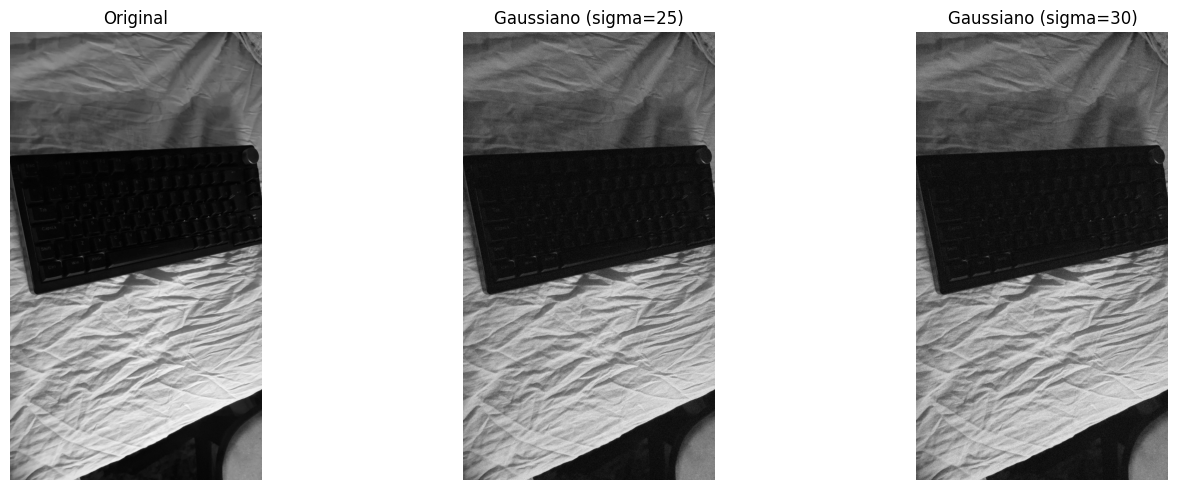

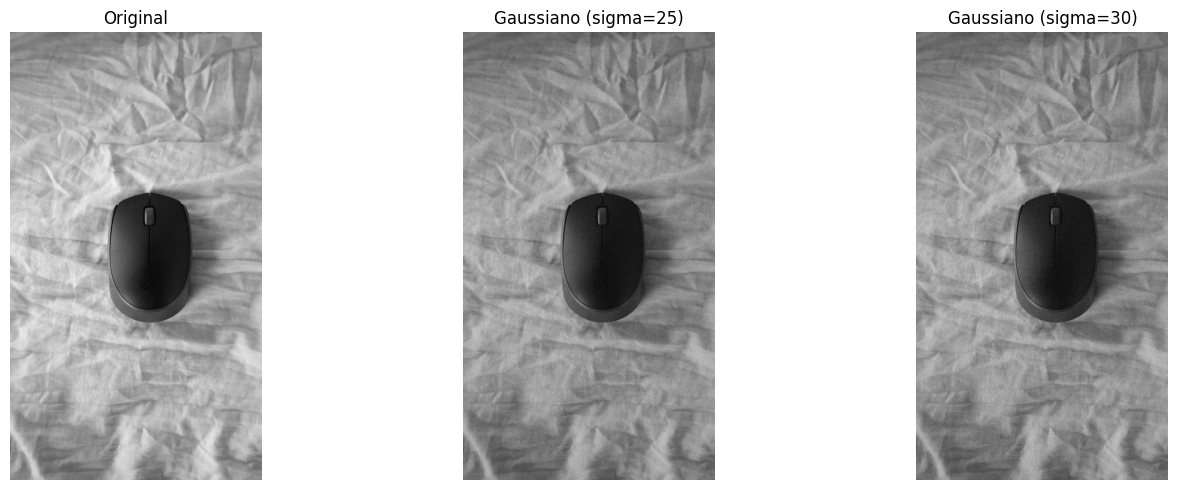

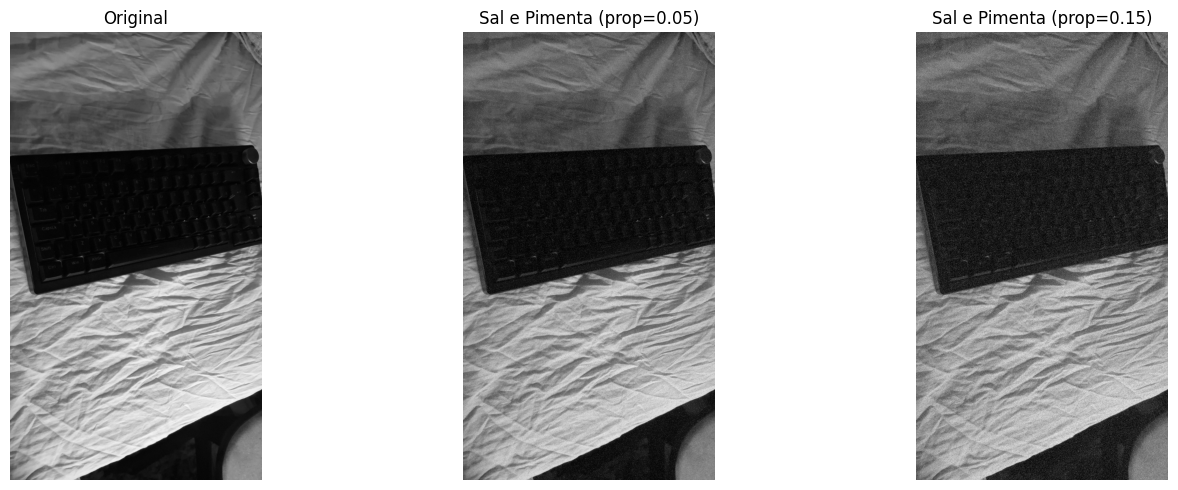

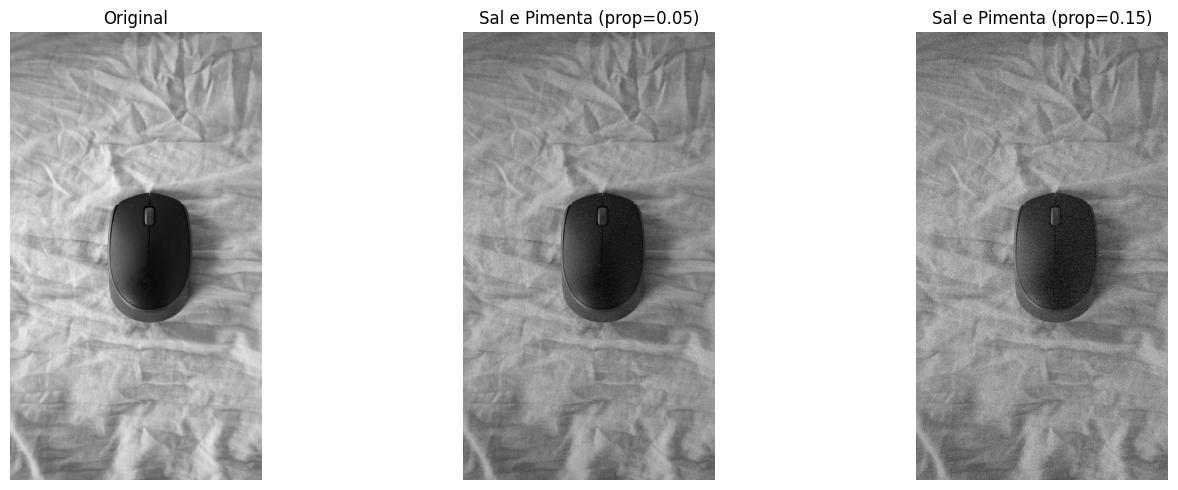

In [17]:
# Inicializando o gerador de números aleatórios (RNG) padrão do NumPy,
RNG = np.random.default_rng()
# 1. Ruído Gaussiano
def adicionar_ruido_gaussiano(imagem, sigma=12):
    # Gera ruído Gaussiano
    ruido = RNG.normal(0, sigma, imagem.shape)
    imagem_ruidosa = imagem.astype(np.float32) + ruido
    imagem_ruidosa = np.clip(imagem_ruidosa, 0, 255) # Limita os valores
    return imagem_ruidosa.astype(np.uint8)

# 2. Ruído Sal e Pimenta
def adicionar_sal_pimenta(imagem, proporcao=0.015):
    saida = imagem.copy() # Cria uma cópia para preservar a imagem original
    quantidade = int(proporcao * saida.size) # Calcula quantos pixels serão alterados
    ys = RNG.integers(0, saida.shape[0], size=quantidade) # Sorteia as coordenadas verticais
    xs = RNG.integers(0, saida.shape[1], size=quantidade) # Sorteia as coordenadas horizontais
    metade = quantidade // 2 # Divide os pixels sorteados em dois grupos
    saida[ys[:metade], xs[:metade]] = 0 # Define o primeiro grupo como pixels pretos (pimenta)
    saida[ys[metade:], xs[metade:]] = 255 # Define o segundo grupo como pixels brancos (sal)
    return saida

# Aplicando as funções nas suas imagens
# 2. Carregando as DUAS imagens (Classe A e Classe B) já em escala de cinza
img_A = cv2.imread('/content/dataset/classe_Teclado/img001_original.jpg', cv2.IMREAD_GRAYSCALE)
img_B = cv2.imread('/content/dataset/classe_Mouse/img008_original.jpg', cv2.IMREAD_GRAYSCALE)

# 3. Gerando DUAS versões ruidosas do tipo Sal e Pimenta para a Imagem A
img01_A_sp = adicionar_sal_pimenta(img_A, proporcao=0.05)
img01_B_sp = adicionar_sal_pimenta(img_A, proporcao=0.15)

# 3. Gerando DUAS versões ruidosas do tipo Sal e Pimenta para a Imagem B
img08_A_sp = adicionar_sal_pimenta(img_B, proporcao=0.05)
img08_B_sp = adicionar_sal_pimenta(img_B, proporcao=0.15)

# 4. Gerando DUAS versões ruidosas do tipo Gaussiano para a Imagem A
img01_A_gauss = adicionar_ruido_gaussiano(img_A, sigma=25)
img01_B_gauss = adicionar_ruido_gaussiano(img_A, sigma=30)


# 4. Gerando DUAS versões ruidosas do tipo Gaussiano para a Imagem B
img08_A_gauss = adicionar_ruido_gaussiano(img_B, sigma=25)
img08_B_gauss = adicionar_ruido_gaussiano(img_B, sigma=30)

# Visualizando os resultados
show_panel(
    [img_A, img01_A_gauss, img01_B_gauss],
    ['Original', 'Gaussiano (sigma=25)', 'Gaussiano (sigma=30)'],
    1, 3, figsize=(15, 5)
)

show_panel(
    [img_B, img08_A_gauss, img08_B_gauss],
    ['Original', 'Gaussiano (sigma=25)', 'Gaussiano (sigma=30)'],
    1, 3, figsize=(15, 5)
)

show_panel(
    [img_A, img01_A_sp, img01_B_sp],
    ['Original', 'Sal e Pimenta (prop=0.05)', 'Sal e Pimenta (prop=0.15)'],
    1, 3, figsize=(15, 5)
)

show_panel(
    [img_B, img08_A_sp, img08_B_sp],
    ['Original', 'Sal e Pimenta (prop=0.05)', 'Sal e Pimenta (prop=0.15)'],
    1, 3, figsize=(15, 5)
)

## Parte 2: Inserção e Análise de Ruído

### 1. Ruído Gaussiano
* **Parâmetros utilizados:** Média = 0 | Desvio Padrão ($\sigma$) = 25 e 30.
* **Impacto visual observado:** A imagem ganha um aspecto geral de "chuvisco" ou granulação. A textura do tecido e a superfície lisa do rato (mouse) perdem nitidez. Ao aumentar o $\sigma$ de 25 para 30, a degradação aumenta, tornando as bordas do objeto mais embaçadas e difíceis de distinguir do fundo.

**Respostas:**
* **O ruído está distribuído uniformemente na imagem?** Sim. O ruído gaussiano afeta todos os píxeis da imagem de forma aditiva, seguindo uma curva de distribuição normal. Não há nenhuma região poupada.
* **Que tipo de problema esse ruído pode causar para algoritmos de visão computacional?** Ele introduz altas frequências artificiais (variações abruptas de intensidade entre píxeis vizinhos). Isso confunde severamente detectores de borda baseados em gradiente (como Sobel e Canny), gerando falsos positivos (bordas que não existem) e dificultando tarefas de segmentação ou reconhecimento de padrões.

---

### 2. Ruído Sal e Pimenta
* **Porcentagem de pixels alterados:** 5% (proporção = 0.05) e 15% (proporção = 0.15).

**Respostas:**
* **Como esse ruído se diferencia visualmente do ruído gaussiano?** Enquanto o gaussiano altera levemente todos os píxeis, o ruído Sal e Pimenta afeta apenas uma percentagem específica da imagem, mas de forma extrema. Ele destrói completamente a informação original do píxel atingido, substituindo-a por preto (pimenta) ou branco (sal). Visualmente, cria pontos de alto contraste salpicados sobre a imagem (muito perceptíveis na imagem do teclado com 15%).
* **Em quais situações esse ruído aparece em sistemas reais de captura de imagem?** Ocorre tipicamente devido a falhas no hardware do sensor (como píxeis mortos ou super-excitados), ruído térmico extremo, erros na conversão analógico-digital ou perda de pacotes durante a transmissão de dados da imagem.

# **Aplicação do Filtro Passa-*Baixa* Gaussiano**

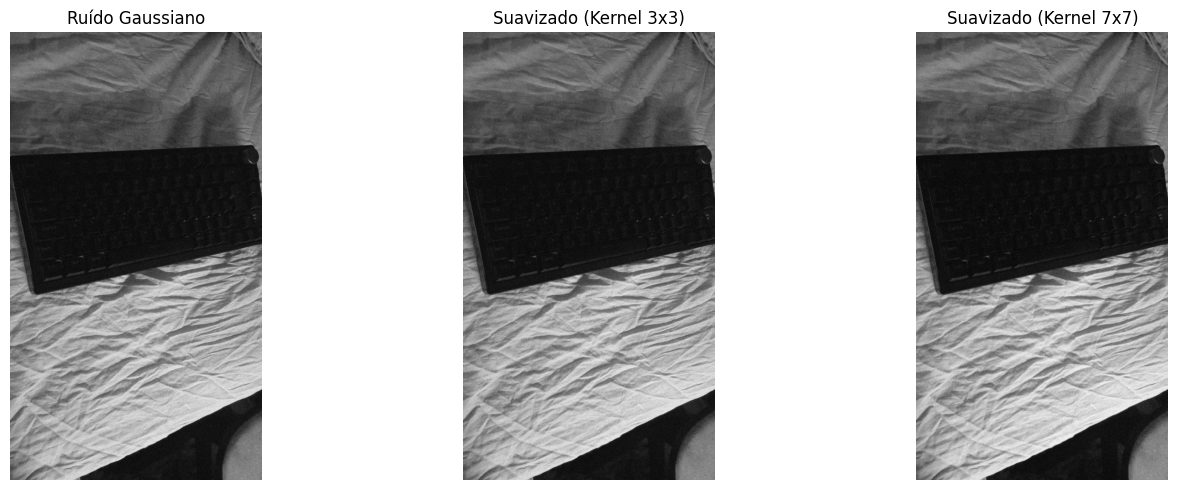

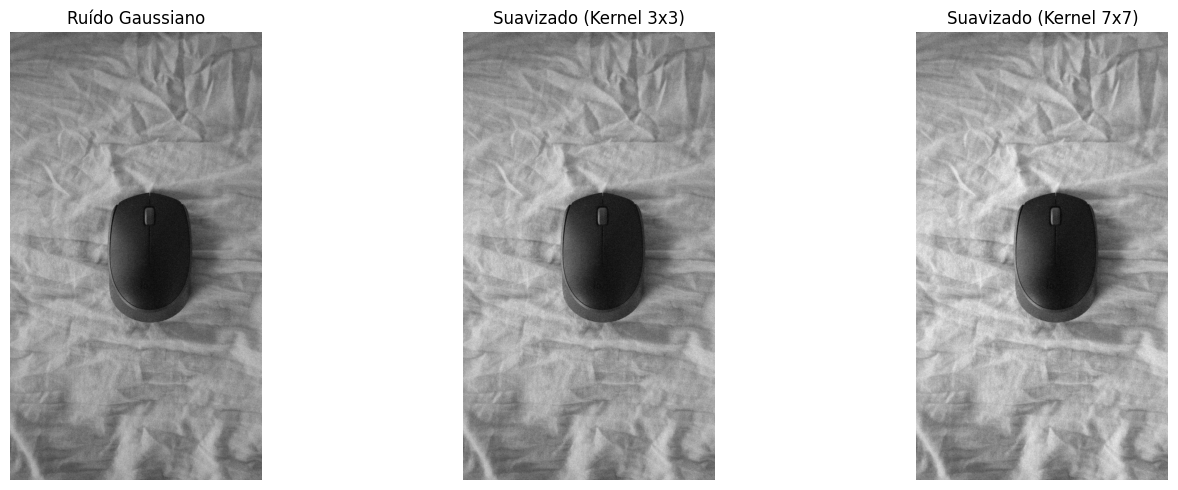

In [18]:
# Aplicando suavização na imagem com ruído Gaussiano
img_blur_3x3_A = cv2.GaussianBlur(img01_B_gauss, (3, 3), 0)
img_blur_7x7_A = cv2.GaussianBlur(img01_B_gauss, (7, 7), 0)

show_panel(
    [img01_B_gauss, img_blur_3x3_A, img_blur_7x7_A],
    ['Ruído Gaussiano', 'Suavizado (Kernel 3x3)', 'Suavizado (Kernel 7x7)'],
    1, 3, figsize=(15, 5)
)

img_blur_3x3_B = cv2.GaussianBlur(img08_B_gauss, (3, 3), 0)
img_blur_7x7_B = cv2.GaussianBlur(img08_B_gauss, (7, 7), 0)

show_panel(
    [img08_B_gauss, img_blur_3x3_B, img_blur_7x7_B],
    ['Ruído Gaussiano', 'Suavizado (Kernel 3x3)', 'Suavizado (Kernel 7x7)'],
    1, 3, figsize=(15, 5)
)

## Parte 3: Aplicação de Filtro Passa-Baixa Gaussiano

**Análise dos Resultados (Comparação Visual):**

* **O filtro conseguiu reduzir o ruído?**
Sim. Observando as imagens suavizadas em comparação com as que contêm ruído gaussiano, fica claro que o filtro passa-baixa atenuou a granulação. O efeito de "chuvisco" foi espalhado, tornando as superfícies (como o tecido de fundo e o corpo do rato) mais homogêneas.

* **Que detalhes da imagem foram perdidos?**
A nitidez geral da imagem e os detalhes finos de alta frequência foram comprometidos. As dobras e vincos do tecido perderam textura, e os contornos nítidos do teclado e do rato ficaram levemente embaçados (desfocados). No caso do kernel 7x7, a perda é severa, chegando a borrar a separação entre as teclas do teclado.

* **Qual kernel apresentou melhor equilíbrio entre suavização e preservação de detalhes?**
O **Kernel 3x3** apresentou o melhor compromisso. Ele foi capaz de reduzir a agressividade do ruído inicial sem destruir completamente a estrutura dos objetos. Já o Kernel 7x7 causou um nível de "blur" (desfoque) excessivo, o que prejudicaria etapas futuras de visão computacional (como extração de features ou detecção de contornos com Canny ou Sobel), uma vez que as bordas reais se misturaram demasiado com o fundo.

# **Aplicação do Filtro Passa-Alta Gaussiano**

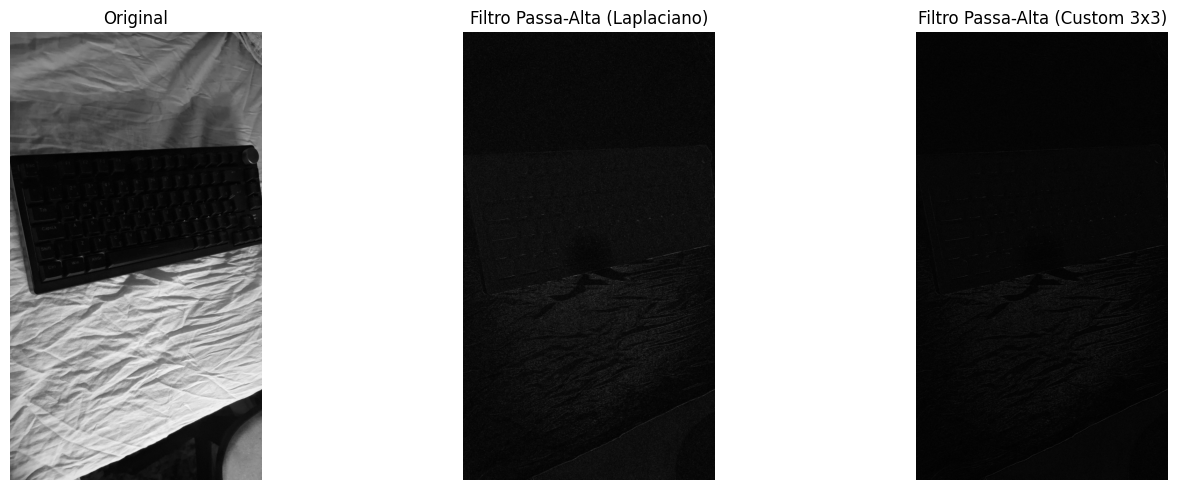

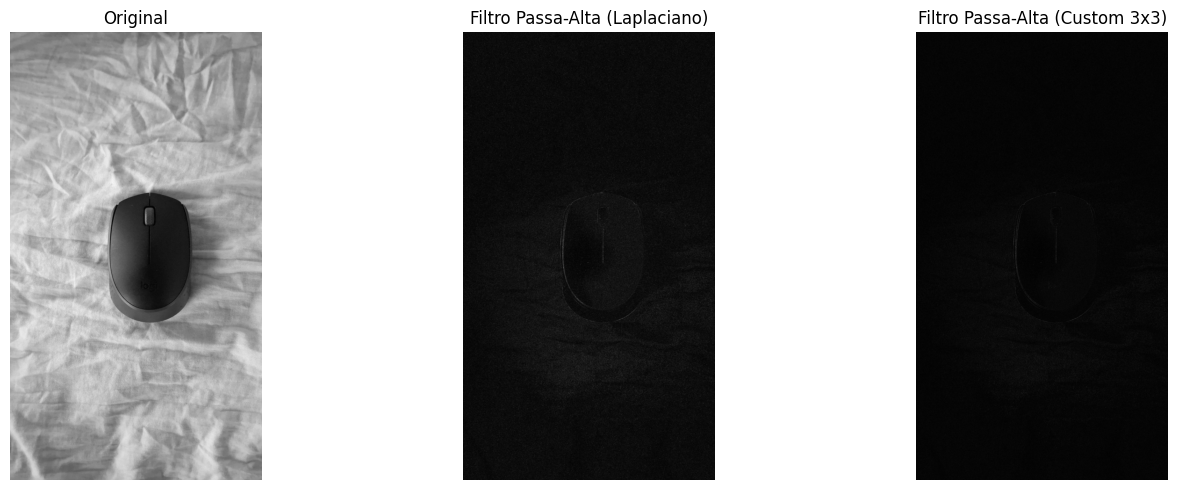

In [19]:
## Aplicando Filtro Passa-Alta na Imagem da classe A

# Usando Laplaciano (Realce de bordas)
laplacian = cv2.Laplacian(img_A, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

# Usando um Kernel High-pass Clássico customizado
kernel_hp = np.array([[-1, -1, -1],
                      [-1,  8, -1],
                      [-1, -1, -1]])
high_pass = cv2.filter2D(img_A, -1, kernel_hp)

show_panel(
    [img_A, laplacian, high_pass],
    ['Original', 'Filtro Passa-Alta (Laplaciano)', 'Filtro Passa-Alta (Custom 3x3)'],
    1, 3, figsize=(15, 5)
)


## Aplicando Filtro Passa-Alta na Imagem da classe B

# Usando Laplaciano (Realce de bordas)
laplacian = cv2.Laplacian(img_B, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

# Usando um Kernel High-pass Clássico customizado
kernel_hp = np.array([[-1, -1, -1],
                      [-1,  8, -1],
                      [-1, -1, -1]])
high_pass = cv2.filter2D(img_B, -1, kernel_hp)

show_panel(
    [img_B, laplacian, high_pass],
    ['Original', 'Filtro Passa-Alta (Laplaciano)', 'Filtro Passa-Alta (Custom 3x3)'],
    1, 3, figsize=(15, 5)
)



## Parte 4: Aplicação de Filtro Passa-Alta

**Análise dos Resultados (Comparação Visual):**

* **Que estruturas da imagem foram destacadas?**
Foram destacadas todas as áreas com transições abruptas de intensidade luminosa (altas frequências)[cite: 44]. Isto inclui os vincos e as dobras do tecido no fundo, a silhueta geométrica do rato (mouse) e os contornos do teclado[cite: 44]. As áreas planas e com iluminação contínua foram suprimidas, ficando quase totalmente escuras[cite: 44].

* **Bordas ficaram mais visíveis?**
Sim, as bordas tornaram-se o único elemento visível, aparecendo como linhas claras sobre um fundo preto[cite: 44]. O filtro passa-alta isolou os gradientes, tornando os contornos dos objetos muito mais evidentes do que na imagem original[cite: 44]. O filtro "Custom 3x3" parece ter destacado as bordas de forma ligeiramente mais intensa que o Laplaciano em algumas áreas[cite: 44].

* **Esse tipo de filtro ajudaria em quais tarefas de visão computacional?**
Este tipo de filtro é fundamental para tarefas de **deteção de contornos**, **segmentação baseada em bordas**, e **reconhecimento de formas/silhuetas**. Seria extremamente útil em inspeções industriais (para medir peças ou encontrar defeitos), leitura de caracteres (OCR) ou na extração de características (features) topológicas para treinar modelos de Machine Learning.

## Parte 5: Comparação Final

**Tabela de Resultados Observados - Imagem B (Mouse):**

| Etapa | Resultado observado |
| :--- | :--- |
| **Imagem original** | Objeto central escuro e liso sobre um fundo texturizado (tecido com vincos). Contornos bem definidos. |
| **Imagem com ruído gaussiano** | Granulação generalizada. A textura do tecido mistura-se com o ruído, e o rato perde a nitidez nas bordas. |
| **Imagem com ruído sal e pimenta** | Pontos pretos e brancos intensos quebram a superfície lisa do rato e poluem o fundo, criando altos contrastes isolados. |
| **Imagem filtrada com gaussian** | O ruído foi atenuado, mas a imagem sofreu desfoque (blur). No kernel 7x7, o rato e os vincos do tecido ficaram quase sem definição. |
| **Imagem com filtro passa-alta** | Áreas planas ficaram pretas. Os contornos curvos do rato e as linhas das dobras do tecido "acenderam" em branco, destacando apenas os gradientes. |

---

**Tabela de Resultados Observados - Imagem A (Teclado):**

| Etapa | Resultado observado |
| :--- | :--- |
| **Imagem original** | Objeto complexo com muitos detalhes finos (as linhas separatórias entre as teclas) sobre o fundo de tecido. |
| **Imagem com ruído gaussiano** | O ruído de alta frequência confunde-se com as linhas das teclas, tornando a estrutura da grade do teclado muito mais difícil de discernir. |
| **Imagem com ruído sal e pimenta** | Os pontos extremos (0 e 255) bloqueiam completamente a visão em partes aleatórias, destruindo detalhes finos como o formato das teclas. |
| **Imagem filtrada com gaussian** | Reduziu o ruído, mas o desfoque foi prejudicial aos detalhes finos. Com o kernel 7x7, as linhas entre as teclas quase desapareceram, fundindo-as numa massa única. |
| **Imagem com filtro passa-alta** | O contorno retangular do teclado e a grade formada por cada tecla isolada foram fortemente realçados contra o fundo negro. |

---

**Respostas à Comparação Final:**

* **Qual ruído degradou mais a imagem?**
Do ponto de vista estrutural, o ruído **Gaussiano** é mais problemático porque afeta todos os píxeis, introduzindo falsos gradientes que confundem os detalhes (como visto na dificuldade de distinguir as teclas do teclado). O ruído **Sal e Pimenta** tem um impacto visual mais agressivo por destruir a informação de píxeis inteiros (deixando-os pretos ou brancos), mas o resto da imagem mantém os gradientes originais.

* **O filtro gaussiano conseguiu recuperar a qualidade visual?**
Não totalmente. O filtro cumpriu o seu papel de atenuar a variação indesejada (suavizando o ruído), mas o custo cobrado foi a introdução de desfoque. Nas duas imagens, as bordas estruturais perderam nitidez e, no caso do teclado, o filtro 7x7 foi tão agressivo que apagou as marcações finas entre as teclas, trocando ruído por perda de informação.

* **Em quais aplicações de visão computacional seria importante aplicar filtros antes do processamento?**
A filtragem prévia é obrigatória em sistemas que dependem da análise de formas, como inspeção de defeitos em peças de fábrica, leitura ótica de caracteres (OCR), reconhecimento facial e sistemas de navegação robótica. Algoritmos de extração de características (como deteção de bordas) são calculados matematicamente através de derivadas espaciais; sem um filtro de suavização inicial, qualquer ruído do sensor resultaria numa explosão de falsas bordas detetadas.